## Nama : Muh. Tenri Kahfi GP
## NIM : H061241084

---

## BAGIAN 2: RESEP 6 (`R-IO-002 / SEISMOLOGI`)
### Case Study: Normalisasi & Analisis Geofisika Katalog Gempa Bumi GeoJSON

#### 1. Latar Belakang Teori Seismologi & Data I/O
Katalog kegempaan global (misalnya dari USGS Earthquake Hazards Program atau BMKG) didistribusikan dalam format standar geospasial `GeoJSON FeatureCollection`. Pada data gempa:
- Koordinat ruang disimpan dalam array 3D: `[longitude, latitude, depth_km]`.
- Konvensi vertikal seismologi adalah *depth positive-down* (kedalaman positif ke bawah bumi dalam kilometer).
- Properti fisik meliputi magnitudo momen ($M_w$), waktu kejadian UTC (*epoch milliseconds*), signifikansi, dan tipe event seismik.

#### 2. Tujuan Analisis Geofisika
Melakukan normalisasi struktur bersarang (*nested JSON*), mengekstrak parameter hiposenter gempa bumi, serta memvisualisasikan zonasi subduksi dan distribusi kedalaman gempa (*focal depth*).

In [4]:
# 1. Pembuatan Dataset Katalog Gempa Bumi Sintetis Realistis (Zona Subduksi)
np.random.seed(42)
n_events = 250

# Simulasi gempa di sepanjang palung zona subduksi (misal Sunda Arc / Busur Indonesia)
lons = np.random.uniform(98.0, 108.0, n_events)
lats = -0.5 * (lons - 98.0) - 2.0 + np.random.normal(0, 0.4, n_events)  # Orientasi palung miring

# Hubungan jarak dari palung terhadap kedalaman subduksi (Wadati-Benioff Zone)
distance_from_trench = (lats - (-0.5 * (lons - 98.0) - 3.5))
depths_km = np.clip(10.0 + 80.0 * np.maximum(distance_from_trench, 0) + np.random.normal(0, 8.0, n_events), 5.0, 300.0)

# Magnitudo Gutenberg-Richter b-value ~ 1.0 (lebih banyak gempa kecil)
magnitudes = 3.5 + np.random.exponential(scale=0.8, size=n_events)
magnitudes = np.clip(magnitudes, 3.5, 7.6)

# 2. Struktur Data GeoJSON FeatureCollection
geojson_features = []
for i in range(n_events):
    feature = {
        "type": "Feature",
        "id": f"eq_2026_{i:04d}",
        "geometry": {
            "type": "Point",
            "coordinates": [float(lons[i]), float(lats[i]), float(depths_km[i])]  # [lon, lat, depth_km]
        },
        "properties": {
            "mag": float(round(magnitudes[i], 1)),
            "place": f"Subduction Zone Sector {int(lons[i])}",
            "time": int(1760000000000 + i * 3600000 * 4),  # Epoch ms
            "status": "reviewed",
            "type": "earthquake"
        }
    }
    geojson_features.append(feature)

geojson_catalog = {
    "type": "FeatureCollection",
    "metadata": {"title": "USGS Synthesized Regional Earthquake Catalog", "count": n_events},
    "features": geojson_features
}

print(f"GeoJSON FeatureCollection berhasil dibuat dengan {n_events} event gempa!")

GeoJSON FeatureCollection berhasil dibuat dengan 250 event gempa!


In [5]:
# 3. Normalisasi Struktur GeoJSON ke Tabel Pandas (Resep R-IO-002)
normalized_rows = []
for feat in geojson_catalog["features"]:
    coords = feat["geometry"]["coordinates"]
    props = feat["properties"]
    
    row = {
        "event_id": feat["id"],
        "longitude_deg": coords[0],
        "latitude_deg": coords[1],
        "depth_km": coords[2],
        "magnitude": props["mag"],
        "time_utc": pd.to_datetime(props["time"], unit="ms", utc=True),
        "event_type": props["type"]
    }
    normalized_rows.append(row)

df_earthquakes = pd.DataFrame(normalized_rows)

# Klasifikasi Kedalaman Berdasarkan Standar Seismologi
# Dangkal: < 70 km, Menengah: 70 - 300 km, Dalam: > 300 km
df_earthquakes["depth_class"] = pd.cut(
    df_earthquakes["depth_km"],
    bins=[0, 70, 300, 1000],
    labels=["Dangkal (<70 km)", "Menengah (70-300 km)", "Dalam (>300 km)"]
)

print("=== RINGKASAN DATA GEMPA BUMI HASIL NORMALISASI ===")
print(df_earthquakes[["event_id", "longitude_deg", "latitude_deg", "depth_km", "magnitude", "depth_class"]].head(6))
print("\nDistribusi Kategori Kedalaman Gempa:")
print(df_earthquakes["depth_class"].value_counts())

=== RINGKASAN DATA GEMPA BUMI HASIL NORMALISASI ===
       event_id  longitude_deg  latitude_deg    depth_km  magnitude  \
0  eq_2026_0000     101.745401     -4.211418   89.275542        4.5   
1  eq_2026_0001     107.507143     -7.359510   81.080507        5.0   
2  eq_2026_0002     105.319939     -5.838576  118.784045        4.9   
3  eq_2026_0003     103.986585     -4.650733  157.143203        3.9   
4  eq_2026_0004      99.560186     -2.694456  120.311463        4.4   
5  eq_2026_0005      99.559945     -3.278268   89.423399        3.7   

            depth_class  
0  Menengah (70-300 km)  
1  Menengah (70-300 km)  
2  Menengah (70-300 km)  
3  Menengah (70-300 km)  
4  Menengah (70-300 km)  
5  Menengah (70-300 km)  

Distribusi Kategori Kedalaman Gempa:
depth_class
Menengah (70-300 km)    243
Dangkal (<70 km)          7
Dalam (>300 km)           0
Name: count, dtype: int64


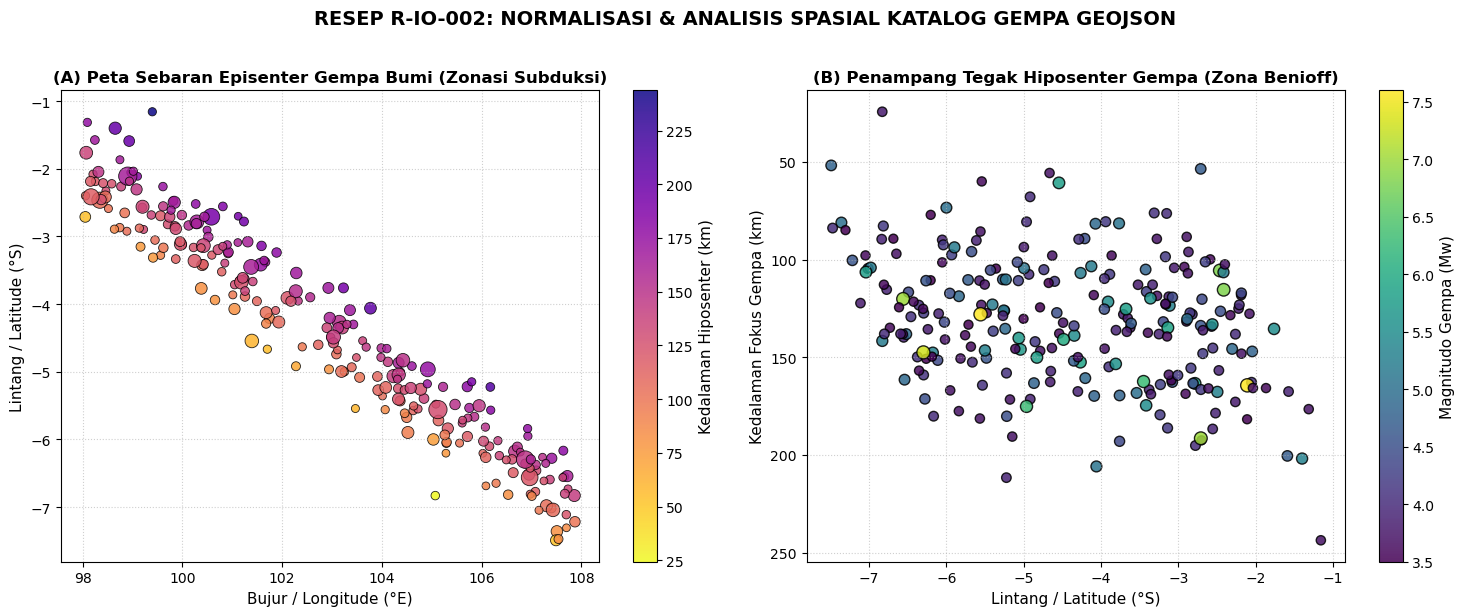

In [6]:
# 4. Visualisasi Sebaran Hiposenter & Magnitudo Gempa Bumi
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot A: Peta Sebaran Episenter (Longitude vs Latitude)
scatter = axes[0].scatter(
    df_earthquakes["longitude_deg"], 
    df_earthquakes["latitude_deg"],
    c=df_earthquakes["depth_km"], 
    s=(df_earthquakes["magnitude"] ** 2.2) * 2.0,
    cmap="plasma_r", 
    edgecolor="black", 
    linewidth=0.6,
    alpha=0.85
)
cbar = fig.colorbar(scatter, ax=axes[0])
cbar.set_label("Kedalaman Hiposenter (km)", fontsize=11)
axes[0].set_title("(A) Peta Sebaran Episenter Gempa Bumi (Zonasi Subduksi)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Bujur / Longitude (°E)", fontsize=11)
axes[0].set_ylabel("Lintang / Latitude (°S)", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Subplot B: Penampang Tegak Hiposenter (Cross-Section Wadati-Benioff Zone)
scatter2 = axes[1].scatter(
    df_earthquakes["latitude_deg"],
    df_earthquakes["depth_km"],
    c=df_earthquakes["magnitude"],
    s=df_earthquakes["magnitude"] * 12,
    cmap="viridis",
    edgecolor="k",
    alpha=0.85
)
axes[1].invert_yaxis()  # Kedalaman bumi bertambah ke bawah
cbar2 = fig.colorbar(scatter2, ax=axes[1])
cbar2.set_label("Magnitudo Gempa (Mw)", fontsize=11)
axes[1].set_title("(B) Penampang Tegak Hiposenter Gempa (Zona Benioff)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Lintang / Latitude (°S)", fontsize=11)
axes[1].set_ylabel("Kedalaman Fokus Gempa (km)", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.suptitle("RESEP R-IO-002: NORMALISASI & ANALISIS SPASIAL KATALOG GEMPA GEOJSON", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

#### Analisis Resep 6:
- Proses normalisasi berhasil membedah format hierarkis `GeoJSON FeatureCollection` menjadi tabel tabular relasional yang mudah diolah.
- Pada penampang tegak hiposenter (B), terlihat jelas pola penunjaman lempeng samudera ke bawah lempeng benua (*Wadati-Benioff Zone*), di mana gempa dangkal ($< 70\text{ km}$) terkonsentrasi di dekat palung (selatan), sedangkan gempa menengah hingga dalam ($> 150\text{ km}$) terjadi semakin jauh ke arah utara di bawah busur vulkanik.